<a href="https://colab.research.google.com/github/AK888-hp/ML-II_Lab/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- 1. Initial Inspection ---
Dataset Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



--- 2. Data Types & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB

Missing Values Count:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Shape after dropping NaNs: (333, 7)

--- 3. Summary Statistics ---


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057
std,5.468668,1.969235,14.015765,805.215802
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.600000,18.700000,213.000000,4775.000000
max,59.600000,21.500000,231.000000,6300.000000


,species,island,sex
count,333,333,333
unique,3,3,2
top,Adelie,Biscoe,Male
freq,146,163,168


/tmp/ipykernel_1386/1920507111.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="species", ax=axes[1], palette="pastel")


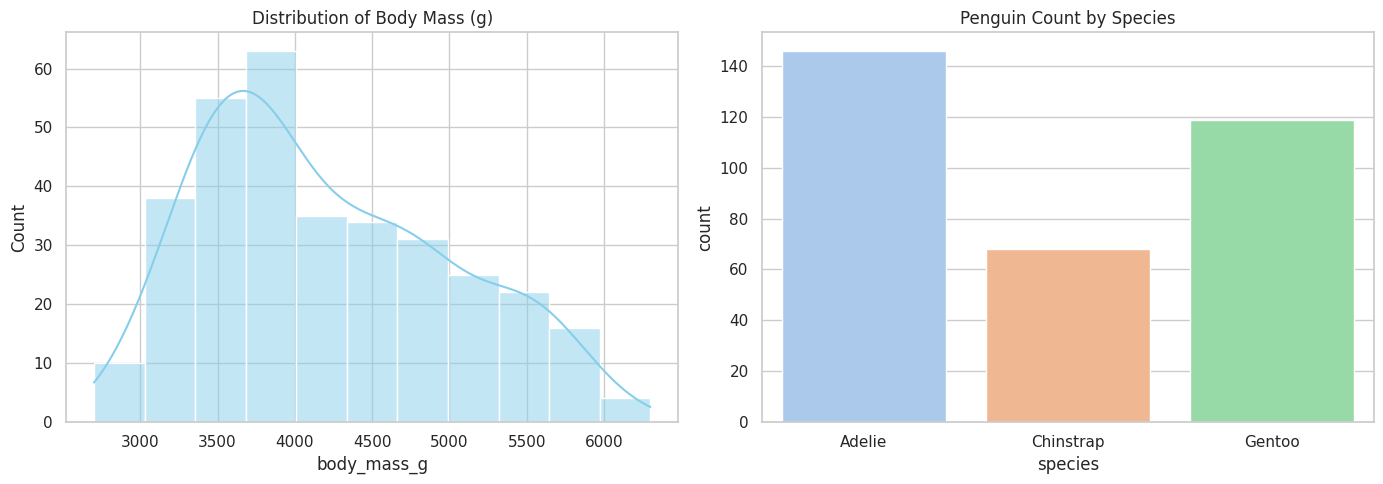

/tmp/ipykernel_1386/1920507111.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="species", y="flipper_length_mm", ax=axes[0], palette="pastel")


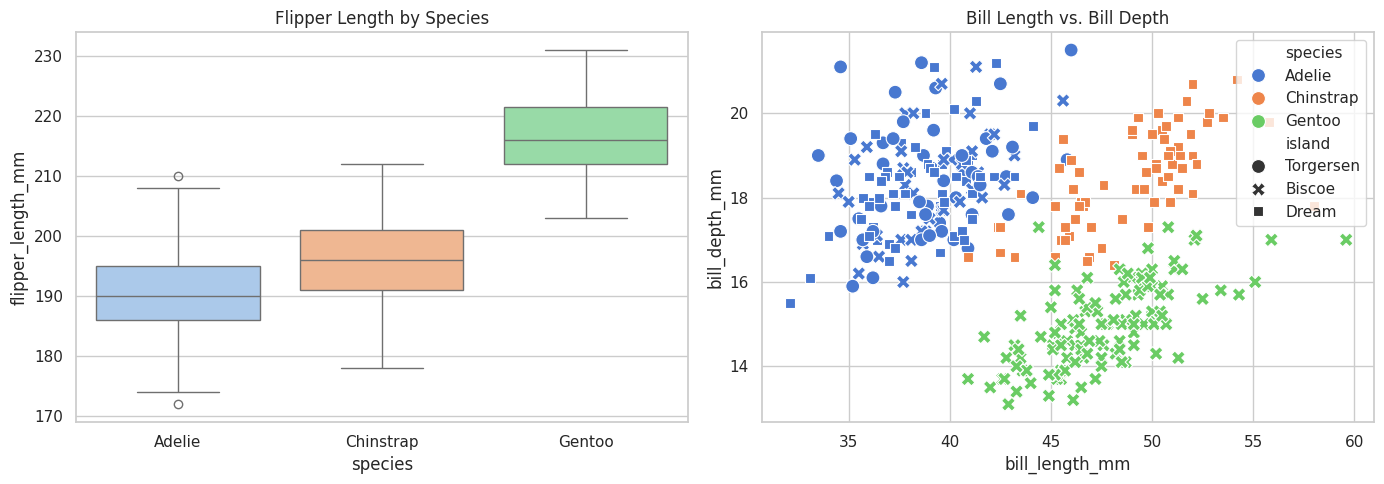


--- 4. Correlation Analysis ---


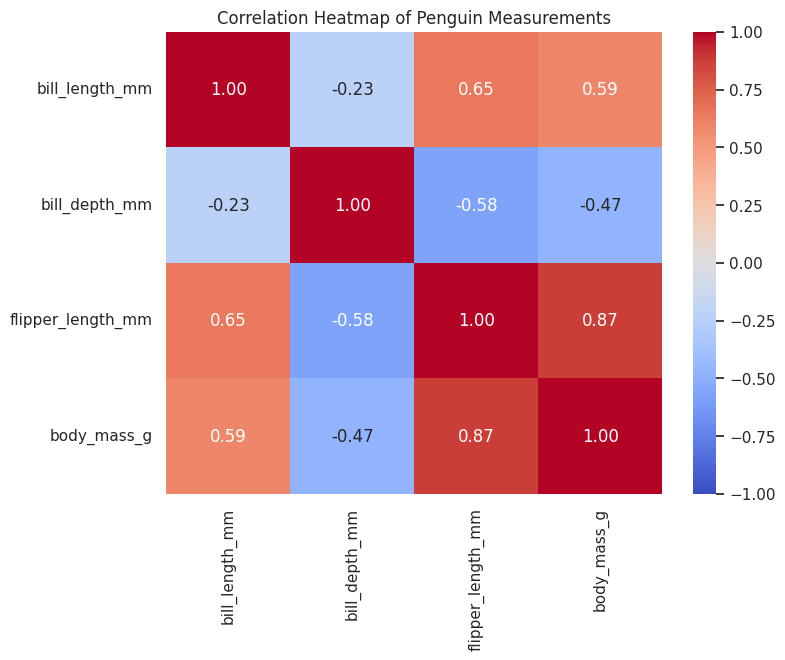


--- 5. Pairwise Relationships ---


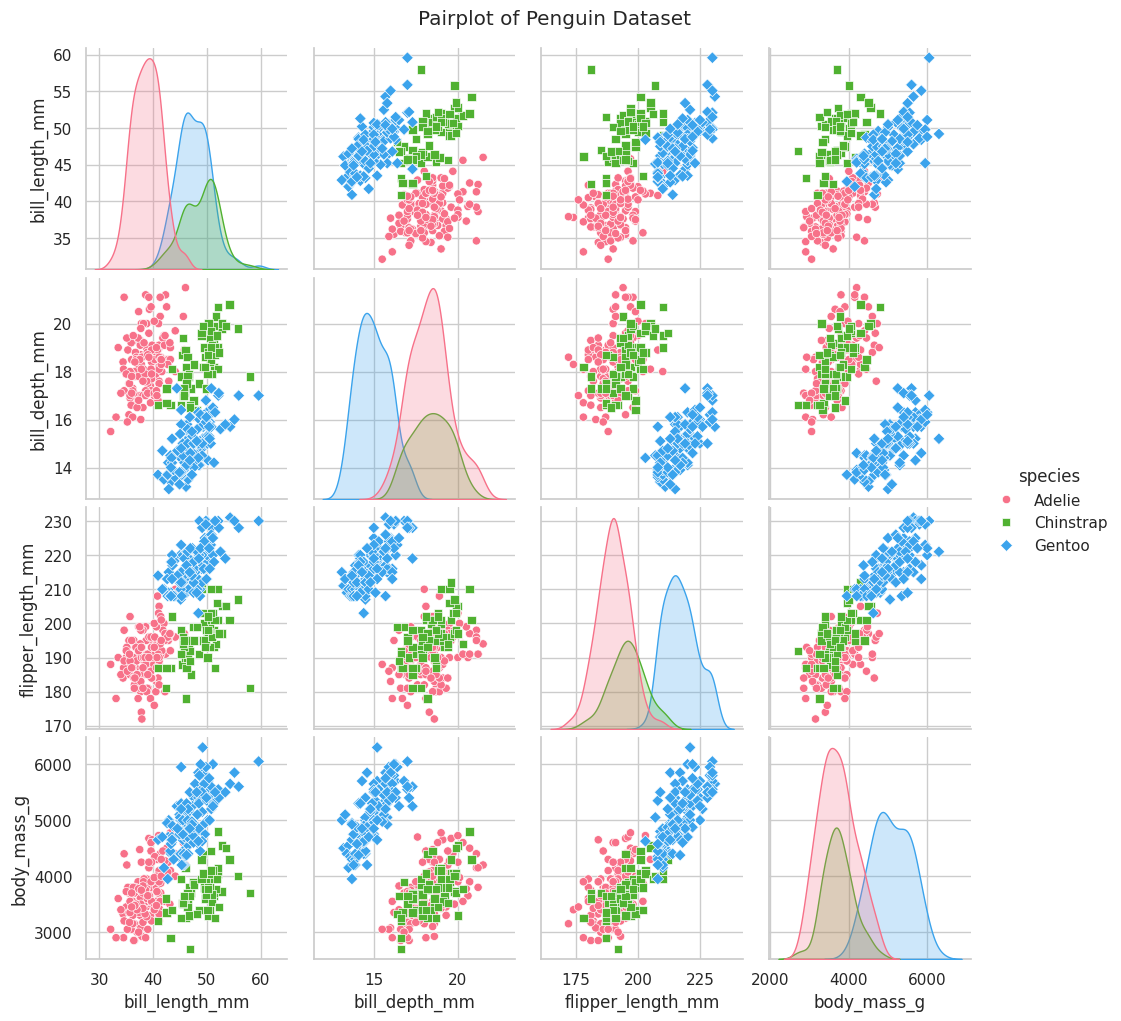

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme
sns.set_theme(style="whitegrid", palette="muted")

# 1. Load the Seaborn Dataset
# The 'penguins' dataset contains size measurements for three penguin species
df = sns.load_dataset('penguins')

print("--- 1. Initial Inspection ---")
print(f"Dataset Shape: {df.shape}")
display(df.head()) # Use print(df.head()) if running as a script

print("\n--- 2. Data Types & Missing Values ---")
df.info()
print("\nMissing Values Count:")
print(df.isnull().sum())

# Clean the data: For this EDA, we'll drop the rows with missing values
# (only 11 rows out of 344 have missing data)
df_clean = df.dropna()
print(f"\nShape after dropping NaNs: {df_clean.shape}")

print("\n--- 3. Summary Statistics ---")
display(df_clean.describe())
display(df_clean.describe(include=['object']))

# 4. Univariate Analysis (Individual Variables)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of a numerical variable
sns.histplot(data=df_clean, x="body_mass_g", kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Body Mass (g)')

# Count of a categorical variable
sns.countplot(data=df_clean, x="species", ax=axes[1], palette="pastel")
axes[1].set_title('Penguin Count by Species')
plt.tight_layout()
plt.show()

# 5. Bivariate Analysis (Relationships between variables)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot: Categorical vs Numerical
sns.boxplot(data=df_clean, x="species", y="flipper_length_mm", ax=axes[0], palette="pastel")
axes[0].set_title('Flipper Length by Species')

# Scatterplot: Numerical vs Numerical separated by Category
sns.scatterplot(
    data=df_clean,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    style="island",
    ax=axes[1],
    s=100
)
axes[1].set_title('Bill Length vs. Bill Depth')
plt.tight_layout()
plt.show()

# 6. Multivariate Analysis & Correlations
print("\n--- 4. Correlation Analysis ---")
# Select only numerical columns for correlation matrix
num_cols = df_clean.select_dtypes(include=np.number).columns
corr_matrix = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Penguin Measurements")
plt.show()

# 7. The Ultimate Seaborn Feature: Pairplot
# This plots pairwise relationships across the entire dataset in one grid
print("\n--- 5. Pairwise Relationships ---")
sns.pairplot(df_clean, hue="species", markers=["o", "s", "D"], palette="husl")
plt.suptitle("Pairplot of Penguin Dataset", y=1.02)
plt.show()